<a id="top"></a>
# Grad-CAM mask-strategy comparison

One image per class, one Grad-CAM per class. **Green = correct prediction, red = wrong.** Model names appear only in the SVG file names.

| Section | What it does |
|---|---|
| [1. Config](#config) | everything you edit |
| [2. Helpers](#helpers) | image loading, overlay, plotting |
| [3. Sample cache](#cache) | downloads 1 image per class **once** into `samples/`, then reuses it |
| [4. Model and Grad-CAM](#model) | `load_model`, Grad-CAM (no mask at inference) |
| [5. Run](#run) | shared run helpers |
| [5a. Dataset experiments](#datasets) | rahman, cohen, kermany: one SVG per dataset, one row per class |
| [5b. mask_exp experiment](#mask-exp) | one test image, one SVG, one row per model |
| [6. Summary](#summary) | accuracy table and anything that was skipped |

<a id="config"></a>
## 1. Config
[top](#top)

- `CAM_LAYER`: `"conv_red_3"` (last `Conv2d` in `model.conv_red_3`), `"enhanced_3"` or `"enhanced_cat"` (input of `transformer_3` / `transformer_cat`).
- `DATASETS[...]["class_names"]` must follow the alphabetical order of the class folders. `samples_subdir` is the folder inside `SAMPLES_DIR`.
- `MODEL_SETS[experiment][dataset]` maps a model name to a weight file relative to `WEIGHTS_DIR`. The model name is only used in SVG file names.
- `MASK_EXP_CLASS` picks the class whose image is used in the mask_exp figure. `LABEL_MODELS_IN_ROWS = True` prints model names on that figure.

In [5]:
from pathlib import Path
import sys

PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / "utils" / "load_model.py").is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Run this notebook from the project directory or one of its subdirectories")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

IMG_SIZE = 224
SEED = 42
CAM_LAYER = "conv_red_3"
CAM_ALPHA = 0.4
SHOW_INLINE = True

PROJECT_DIR = PROJECT_ROOT / "model"
WEIGHTS_DIR = PROJECT_DIR / "weights"
OUT_ROOT = PROJECT_ROOT / "results" / "gradcam_exp"
SAMPLES_DIR = PROJECT_ROOT / "samples"
REFRESH_SAMPLES = False

COLOR_CORRECT = "#1b9e3e"
COLOR_WRONG = "#d62728"

MASK_EXP_CLASS = "COVID-19"
LABEL_MODELS_IN_ROWS = False

DATASETS = {
    "rahman": {
        "title": "Rahman",
        "kaggle": "tawsifurrahman/covid19-radiography-database",
        "subdir": "COVID-19_Radiography_Dataset",
        "only_in_path": "images",
        "class_names": ["COVID-19", "Lung Opacity", "Normal", "Pneumonia"],
        "samples_subdir": "covid19_radiography_4cls",
    },
    "cohen": {
        "title": "Cohen",
        "kaggle": "prashant268/chest-xray-covid19-pneumonia",
        "subdir": "Data/test",
        "only_in_path": None,
        "class_names": ["COVID-19", "Normal", "Pneumonia"],
        "samples_subdir": "chest_xray_covid_3cls",
    },
    "kermany": {
        "title": "Kermany",
        "kaggle": "paultimothymooney/chest-xray-pneumonia",
        "subdir": "chest_xray/test",
        "only_in_path": None,
        "class_names": ["Normal", "Pneumonia"],
        "samples_subdir": "chest_xray_pneumonia_2cls",
    },
}

MODEL_SETS = {
    "datasets": {
        "rahman":  {"rahman_msr":  "eca_LN_rahman42.pth"},
        "cohen":   {"cohen_msr":   "eca_LN_cohen42.pth"},
        "kermany": {"kermany_msr": "eca_LN_kermany42.pth"},
    },
    "mask_exp": {
        "rahman": {
            "input_masked":        "mask_exp/eca_input_mask.pth",
            "feature-level-mask":  "mask_exp/eca_feature_mask.pth",
            "inverted-input-mask": "mask_exp/eca_inverted_mask.pth",
            "mask-image-only":     "mask_exp/eca_mask_img_only.pth",
        },
    },
}

<a id="helpers"></a>
## 2. Helpers
[top](#top)

In [6]:
import csv
import json
import random
import re
import shutil
from dataclasses import dataclass

import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from torchvision import transforms
from torchvision.transforms import InterpolationMode

try:
    from IPython.display import Markdown, display
except ImportError:
    Markdown = display = None


def slug(text):
    return re.sub(r"[^a-z0-9]+", "_", text.lower()).strip("_")


def heading(text):
    """Show a markdown header in the cell output so it appears in the notebook outline."""
    if display is not None:
        display(Markdown(text))
    else:
        print(text)


@dataclass
class Sample:
    label: int
    img: np.ndarray
    path: str


@dataclass
class Result:
    """Prediction, class probabilities and one Grad-CAM per class."""
    pred: int
    probs: list
    cams: dict
    correct: bool


_to_tensor = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE), interpolation=InterpolationMode.BICUBIC),
    transforms.ToTensor(),
])


def load_image(path):
    x = _to_tensor(Image.open(path).convert("RGB"))
    return x.permute(1, 2, 0).numpy()


def overlay_cam_on_image(img, cam, alpha=CAM_ALPHA):
    """Blend a blurred JET heat-map of `cam` over `img`."""
    img_u8 = (np.clip(img, 0, 1) * 255).astype(np.uint8)
    h, w = img_u8.shape[:2]
    cam = np.asarray(cam, dtype=np.float32)
    if cam.shape != (h, w):
        cam = cv2.resize(cam, (w, h))
    cam = cv2.GaussianBlur(cam, (0, 0), sigmaX=6)
    cam = cam / (cam.max() + 1e-8)
    heat = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)
    return cv2.addWeighted(img_u8, 1 - alpha, heat, alpha, 0)


def draw_panel(ax, image, title, color=None):
    """Show an image with a title; a color adds a frame and colors the title."""
    ax.imshow(image)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(color is not None)
        if color is not None:
            spine.set_edgecolor(color)
            spine.set_linewidth(3.5)
    ax.set_title(title, color=color or "black", fontsize=11, fontweight="bold" if color else "normal")


def draw_cam_row(axes_row, ds_cfg, sample, res, left_title):
    """Draw [original | Grad-CAM of every class]; the predicted class is framed green (correct) or red (wrong)."""
    names = ds_cfg["class_names"]
    draw_panel(axes_row[0], sample.img, left_title)
    for j in range(len(names)):
        tags = ", ".join(tag for tag, on in (("true", j == sample.label), ("pred", j == res.pred)) if on)
        line1 = names[j] + (f" [{tags}]" if tags else "")
        if j == res.pred:
            color = COLOR_CORRECT if res.correct else COLOR_WRONG
            line2 = f"{'✓' if res.correct else '✗'} {res.probs[j]:.0%}"
        else:
            color, line2 = None, f"{res.probs[j]:.0%}"
        draw_panel(axes_row[j + 1], overlay_cam_on_image(sample.img, res.cams[j]), f"{line1}\n{line2}", color)


def render_figure(ds_cfg, samples, results):
    """One model, one row per class image."""
    names = ds_cfg["class_names"]
    rows, cols = len(results), 1 + len(names)
    fig, axes = plt.subplots(rows, cols, figsize=(3.7 * cols, 4.3 * rows + 0.9), squeeze=False)
    for r, label in enumerate(sorted(results)):
        draw_cam_row(axes[r], ds_cfg, samples[label], results[label], f"True: {names[label]}")
    fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.8, w_pad=1.0)
    return fig


def render_model_rows(ds_cfg, sample, results_by_model):
    """One test image, one row per model in dict order."""
    names = ds_cfg["class_names"]
    rows, cols = len(results_by_model), 1 + len(names)
    fig, axes = plt.subplots(rows, cols, figsize=(3.7 * cols, 4.3 * rows + 0.9), squeeze=False)
    for r, (model_name, res) in enumerate(results_by_model.items()):
        left = f"{model_name}\nTrue: {names[sample.label]}" if LABEL_MODELS_IN_ROWS else f"True: {names[sample.label]}"
        draw_cam_row(axes[r], ds_cfg, sample, res, left)
    fig.tight_layout(rect=(0, 0, 1, 0.97), h_pad=2.8, w_pad=1.0)
    return fig

<a id="cache"></a>
## 3. Sample cache (download once)
[top](#top)

The first run downloads each Kaggle dataset, picks one random image per class, and copies them to `samples/<dataset>/`.
After that the datasets are never touched again: if `samples/<dataset>/manifest.json` exists, `kagglehub` is not even imported.
Use `REFRESH_SAMPLES = True` to pick new images.

In [7]:
IMG_EXTS = (".png", ".jpg", ".jpeg")


def build_cache(ds_name, ds_cfg):
    """Download the dataset, copy one random image per class into SAMPLES_DIR and write a manifest."""
    import kagglehub
    root = Path(kagglehub.dataset_download(ds_cfg["kaggle"])) / ds_cfg["subdir"]
    only = ds_cfg["only_in_path"]
    classes = sorted(p.name for p in root.iterdir() if p.is_dir())
    print(f"[{ds_name}] class folders found: {classes}")
    if len(classes) != len(ds_cfg["class_names"]):
        raise ValueError(f"{ds_name}: {len(classes)} class folders found but class_names lists "
                         f"{len(ds_cfg['class_names'])}; fix class_names or subdir in the config")

    out = SAMPLES_DIR / ds_cfg["samples_subdir"]
    if out.exists():
        shutil.rmtree(out)
    out.mkdir(parents=True)
    rng = random.Random(SEED)
    manifest = []
    for c, folder in enumerate(classes):
        files = sorted(f for f in (root / folder).rglob("*")
                       if f.suffix.lower() in IMG_EXTS and (only is None or only in f.parts))
        src = rng.choice(files)
        stem = f"{c:02d}_{slug(ds_cfg['class_names'][c])}"
        shutil.copy(src, out / f"{stem}{src.suffix.lower()}")
        manifest.append({"label": c, "class_folder": folder, "image": f"{stem}{src.suffix.lower()}",
                         "source": src.relative_to(root).as_posix()})
    (out / "manifest.json").write_text(json.dumps(manifest, indent=2))


def load_samples(ds_name, ds_cfg):
    """Return {class index: Sample} from the cache, building the cache first if needed."""
    d = SAMPLES_DIR / ds_cfg["samples_subdir"]
    if REFRESH_SAMPLES or not (d / "manifest.json").exists():
        build_cache(ds_name, ds_cfg)
    else:
        print(f"[{ds_name}] using cached samples in {d}")
    return {e["label"]: Sample(label=e["label"], img=load_image(d / e["image"]), path=e["source"])
            for e in json.loads((d / "manifest.json").read_text())}

<a id="model"></a>
## 4. Model and Grad-CAM
[top](#top)

In [8]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from utils.load_model import load_model


def last_conv2d(module):
    last = None
    for m in module.modules():
        if isinstance(m, nn.Conv2d):
            last = m
    if last is None:
        raise ValueError("No Conv2d layer found")
    return last


class GradCAM:
    """Grad-CAM on one feature map, captured from a module's output (forward hook) or input (forward pre-hook)."""

    def __init__(self, model, module, capture="output"):
        self.model, self.activations, self.gradients = model, None, None
        if capture == "output":
            self.handle = module.register_forward_hook(lambda m, i, o: self._save(o))
        else:
            self.handle = module.register_forward_pre_hook(lambda m, args: self._save(args[0]))

    def _save(self, feat):
        """Keep the feature map and hook its gradient; forwards under no_grad() have no gradient to hook."""
        self.activations = feat
        if feat.requires_grad:
            feat.register_hook(lambda g: setattr(self, "gradients", g))

    def remove(self):
        self.handle.remove()

    def __call__(self, forward, class_idx):
        """Grad-CAM of `class_idx`; `forward` is a zero-argument callable returning the logits."""
        self.model.zero_grad(set_to_none=True)
        logits = forward()
        logits[:, class_idx].sum().backward()
        weights = self.gradients.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((weights * self.activations).sum(dim=1, keepdim=True))
        cam = F.interpolate(cam, size=(IMG_SIZE, IMG_SIZE), mode="bicubic", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy()


class Predictor:
    """One loaded model: class probabilities and Grad-CAMs on the layer chosen by CAM_LAYER."""

    def __init__(self, model, device):
        self.model, self.device = model, device
        if CAM_LAYER == "conv_red_3":
            self.engine = GradCAM(model, last_conv2d(model.conv_red_3))
        elif CAM_LAYER == "enhanced_3":
            self.engine = GradCAM(model, model.transformer_3, capture="input")
        elif CAM_LAYER == "enhanced_cat":
            self.engine = GradCAM(model, model.transformer_cat, capture="input")
        else:
            raise ValueError(f"unknown CAM_LAYER {CAM_LAYER!r}; use conv_red_3, enhanced_3 or enhanced_cat")

    def _input(self, sample):
        return torch.from_numpy(sample.img).permute(2, 0, 1).unsqueeze(0).to(self.device)

    def predict(self, sample):
        with torch.no_grad():
            probs = torch.softmax(self.model(self._input(sample)), dim=1)[0]
        return int(probs.argmax()), probs.tolist()

    def cam(self, sample, class_idx):
        x = self._input(sample).detach().clone().requires_grad_(True)
        return self.engine(lambda: self.model(x), class_idx)

    def close(self):
        self.engine.remove()


def checkpoint_num_classes(path):
    """Output size of the checkpoint's classifier, or None if it cannot be told."""
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    state = ckpt.get("state_dict", ckpt)
    keys = [k for k in state if k.removeprefix("module.").startswith("classifier")
            and k.endswith("weight") and state[k].ndim == 2]
    return int(state[keys[-1]].shape[0]) if keys else None


def load_predictor(ds_cfg, weights):
    """Build a Predictor, or raise FileNotFoundError / ValueError with a readable reason.

    load_model() skips shape-mismatched tensors and keeps their random init, so a checkpoint with the wrong
    class count would load without error; the class count is checked first.
    """
    weights = Path(weights)
    if not weights.exists():
        raise FileNotFoundError(f"weights not found: {weights}")
    n_classes = len(ds_cfg["class_names"])
    found = checkpoint_num_classes(weights)
    if found is not None and found != n_classes:
        raise ValueError(f"{weights.name} has {found} output classes, this dataset has {n_classes}")

    model, device = load_model(weights, num_classes=n_classes)
    return Predictor(model, device)

c:\Users\dehoa\Downloads\Models\Model Config\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<a id="run"></a>
## 5. Run
[top](#top)

The cell below only defines helpers. Run it once, then run 5a, 5b or both, in any order. Re-running an experiment cell
replaces its own results. SVGs go to `results/gradcam_exp/<experiment>/`.

In [9]:
summary_rows, skipped = [], []
samples_cache = {}


def get_samples(ds_name, ds_cfg):
    if ds_name not in samples_cache:
        samples_cache[ds_name] = load_samples(ds_name, ds_cfg)
    return samples_cache[ds_name]


def start_experiment(experiment):
    """Drop the earlier results of `experiment`, create its output folder and return it."""
    summary_rows[:] = [r for r in summary_rows if r["experiment"] != experiment]
    skipped[:] = [s for s in skipped if s[0] != experiment]
    out_dir = OUT_ROOT / experiment
    out_dir.mkdir(parents=True, exist_ok=True)
    return out_dir


def try_load(experiment, ds_name, ds_cfg, model_name, rel_path):
    """Return a Predictor, or None (recording the reason in `skipped`) if the model cannot be loaded."""
    try:
        return load_predictor(ds_cfg, WEIGHTS_DIR / rel_path)
    except (FileNotFoundError, ValueError) as e:
        skipped.append((experiment, ds_name, model_name, str(e)))
        print(f"  SKIPPED {model_name}: {e}")
        return None


def evaluate(predictor, experiment, ds_name, ds_cfg, samples, model_name, class_ids):
    """Predict each image in class_ids and compute a Grad-CAM for every class; closes the predictor."""
    names, results = ds_cfg["class_names"], {}
    for c in class_ids:
        sample = samples[c]
        pred, probs = predictor.predict(sample)
        cams = {j: predictor.cam(sample, j) for j in range(len(names))}
        results[c] = Result(pred, probs, cams, pred == sample.label)
        summary_rows.append({"experiment": experiment, "dataset": ds_name, "model": model_name,
                             "true_class": names[c], "pred_class": names[pred],
                             "confidence": round(probs[pred], 4), "prob_true_class": round(probs[c], 4),
                             "correct": results[c].correct, "image": sample.path})
    predictor.close()
    return results


def save(fig, path):
    fig.savefig(path, format="svg")
    if SHOW_INLINE:
        plt.show()
    plt.close(fig)

<a id="datasets"></a>
### 5a. Dataset experiments
[top](#top)

One SVG per dataset and model, one row per class.

#### datasets: Rahman (`rahman`, 4 classes)

[rahman] using cached samples in c:\Users\dehoa\Downloads\Models\Model Config\samples\covid19_radiography_4cls


c:\Users\dehoa\Downloads\Models\Model Config\myenv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
c:\Users\dehoa\Downloads\Models\Model Config\myenv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)



Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!


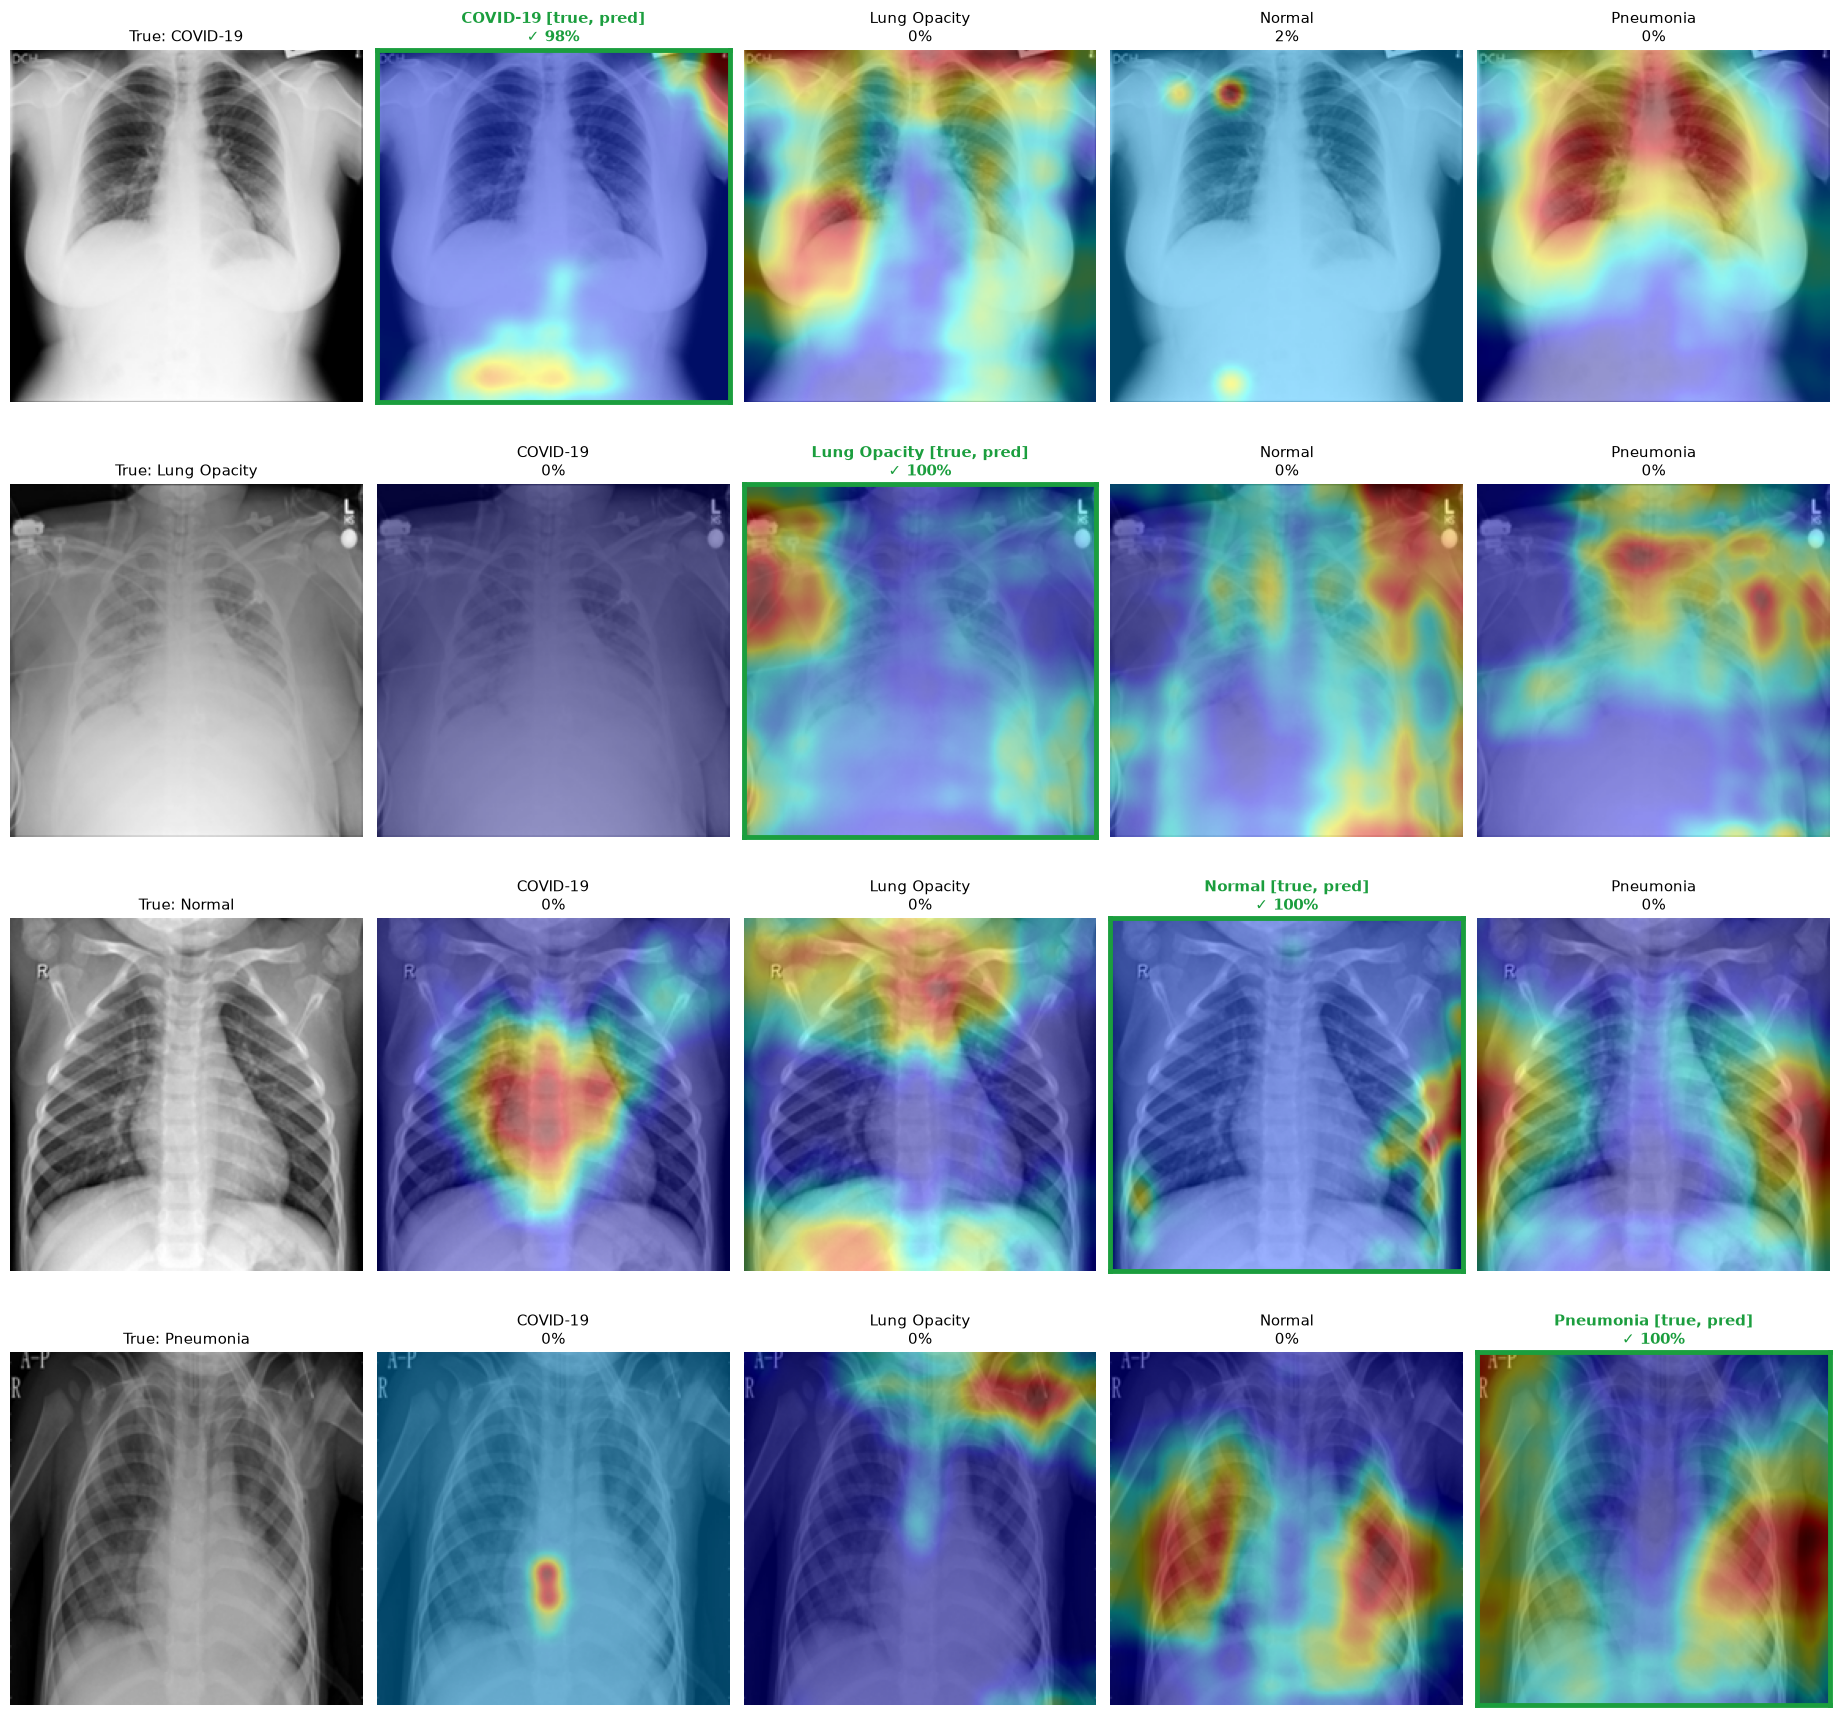

  rahman_msr: 4/4 correct


#### datasets: Cohen (`cohen`, 3 classes)

[cohen] using cached samples in c:\Users\dehoa\Downloads\Models\Model Config\samples\chest_xray_covid_3cls

Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!


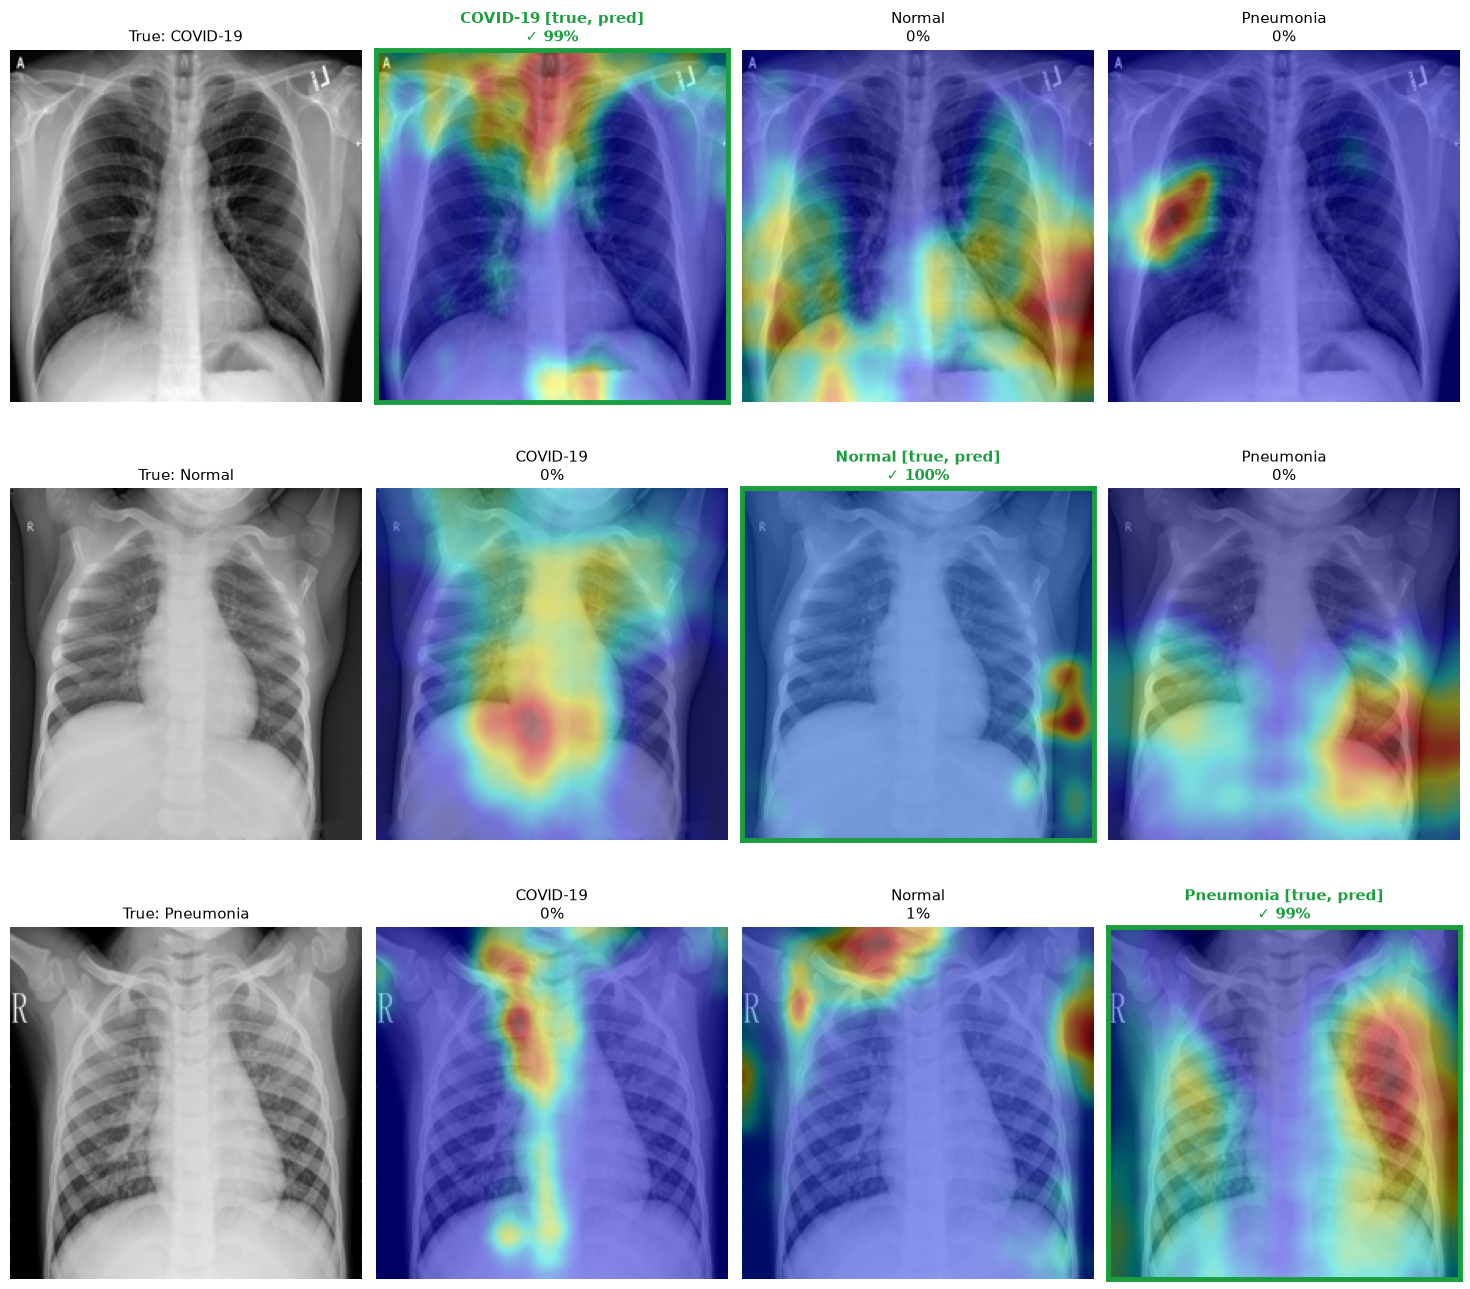

  cohen_msr: 3/3 correct


#### datasets: Kermany (`kermany`, 2 classes)

[kermany] using cached samples in c:\Users\dehoa\Downloads\Models\Model Config\samples\chest_xray_pneumonia_2cls

Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!


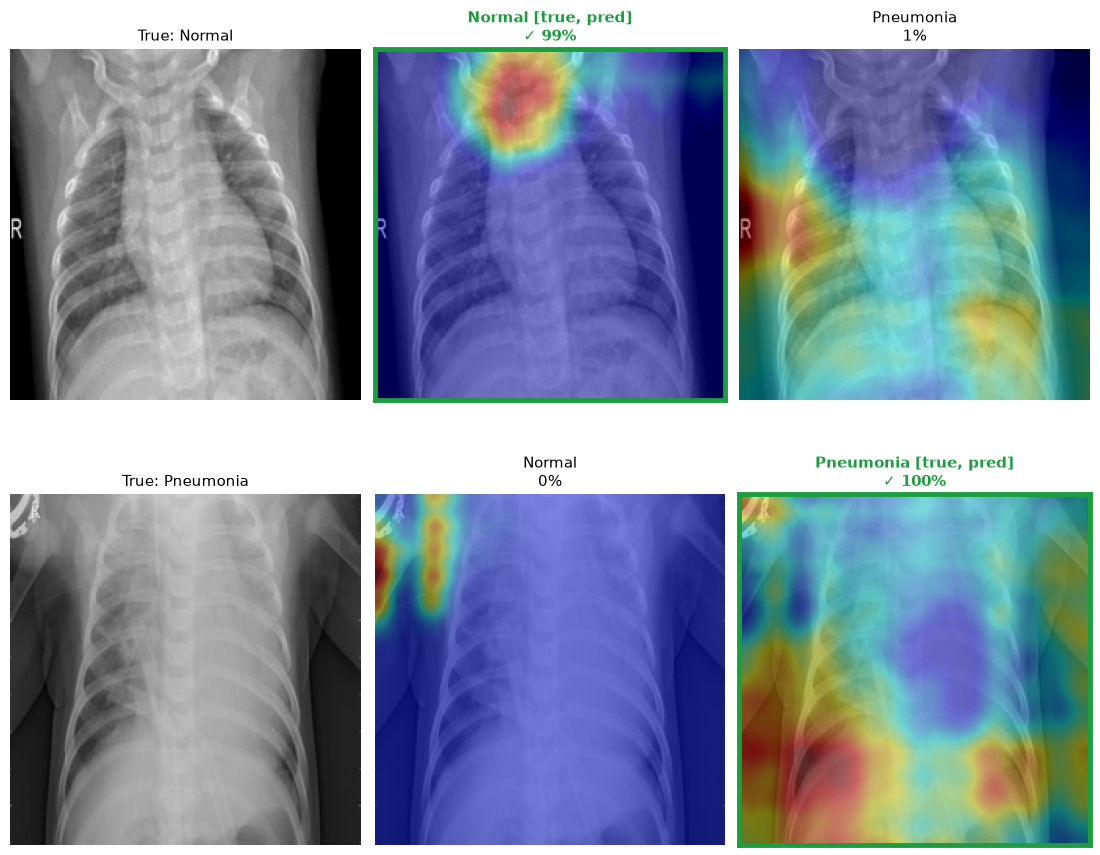

  kermany_msr: 2/2 correct


In [10]:
EXPERIMENT = "datasets"
out_dir = start_experiment(EXPERIMENT)

for ds_name, model_files in MODEL_SETS[EXPERIMENT].items():
    ds_cfg = DATASETS[ds_name]
    names = ds_cfg["class_names"]
    heading(f"#### {EXPERIMENT}: {ds_cfg['title']} (`{ds_name}`, {len(names)} classes)")
    samples = get_samples(ds_name, ds_cfg)

    for model_name, rel_path in model_files.items():
        predictor = try_load(EXPERIMENT, ds_name, ds_cfg, model_name, rel_path)
        if predictor is None:
            continue
        results = evaluate(predictor, EXPERIMENT, ds_name, ds_cfg, samples, model_name, range(len(names)))
        save(render_figure(ds_cfg, samples, results), out_dir / f"{ds_name}__{slug(model_name)}.svg")
        print(f"  {model_name}: {sum(r.correct for r in results.values())}/{len(names)} correct")

<a id="mask-exp"></a>
### 5b. mask_exp experiment
[top](#top)

One test image (`MASK_EXP_CLASS`), one SVG, one row per model in the order of `MODEL_SETS["mask_exp"]`.

#### mask_exp: Rahman (`rahman`, test image: COVID-19)


Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!
  input_masked: correct

Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!
  feature-level-mask: correct

Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!
  inverted-input-mask: correct

Current model parameters not loaded from checkpoint:
  transformer_3.out_norm.bias
  transformer_3.out_norm.weight
  transformer_cat.out_norm.bias
  transformer_cat.out_norm.weight

Custom model loaded successfully!
  mask-image-only: wrong


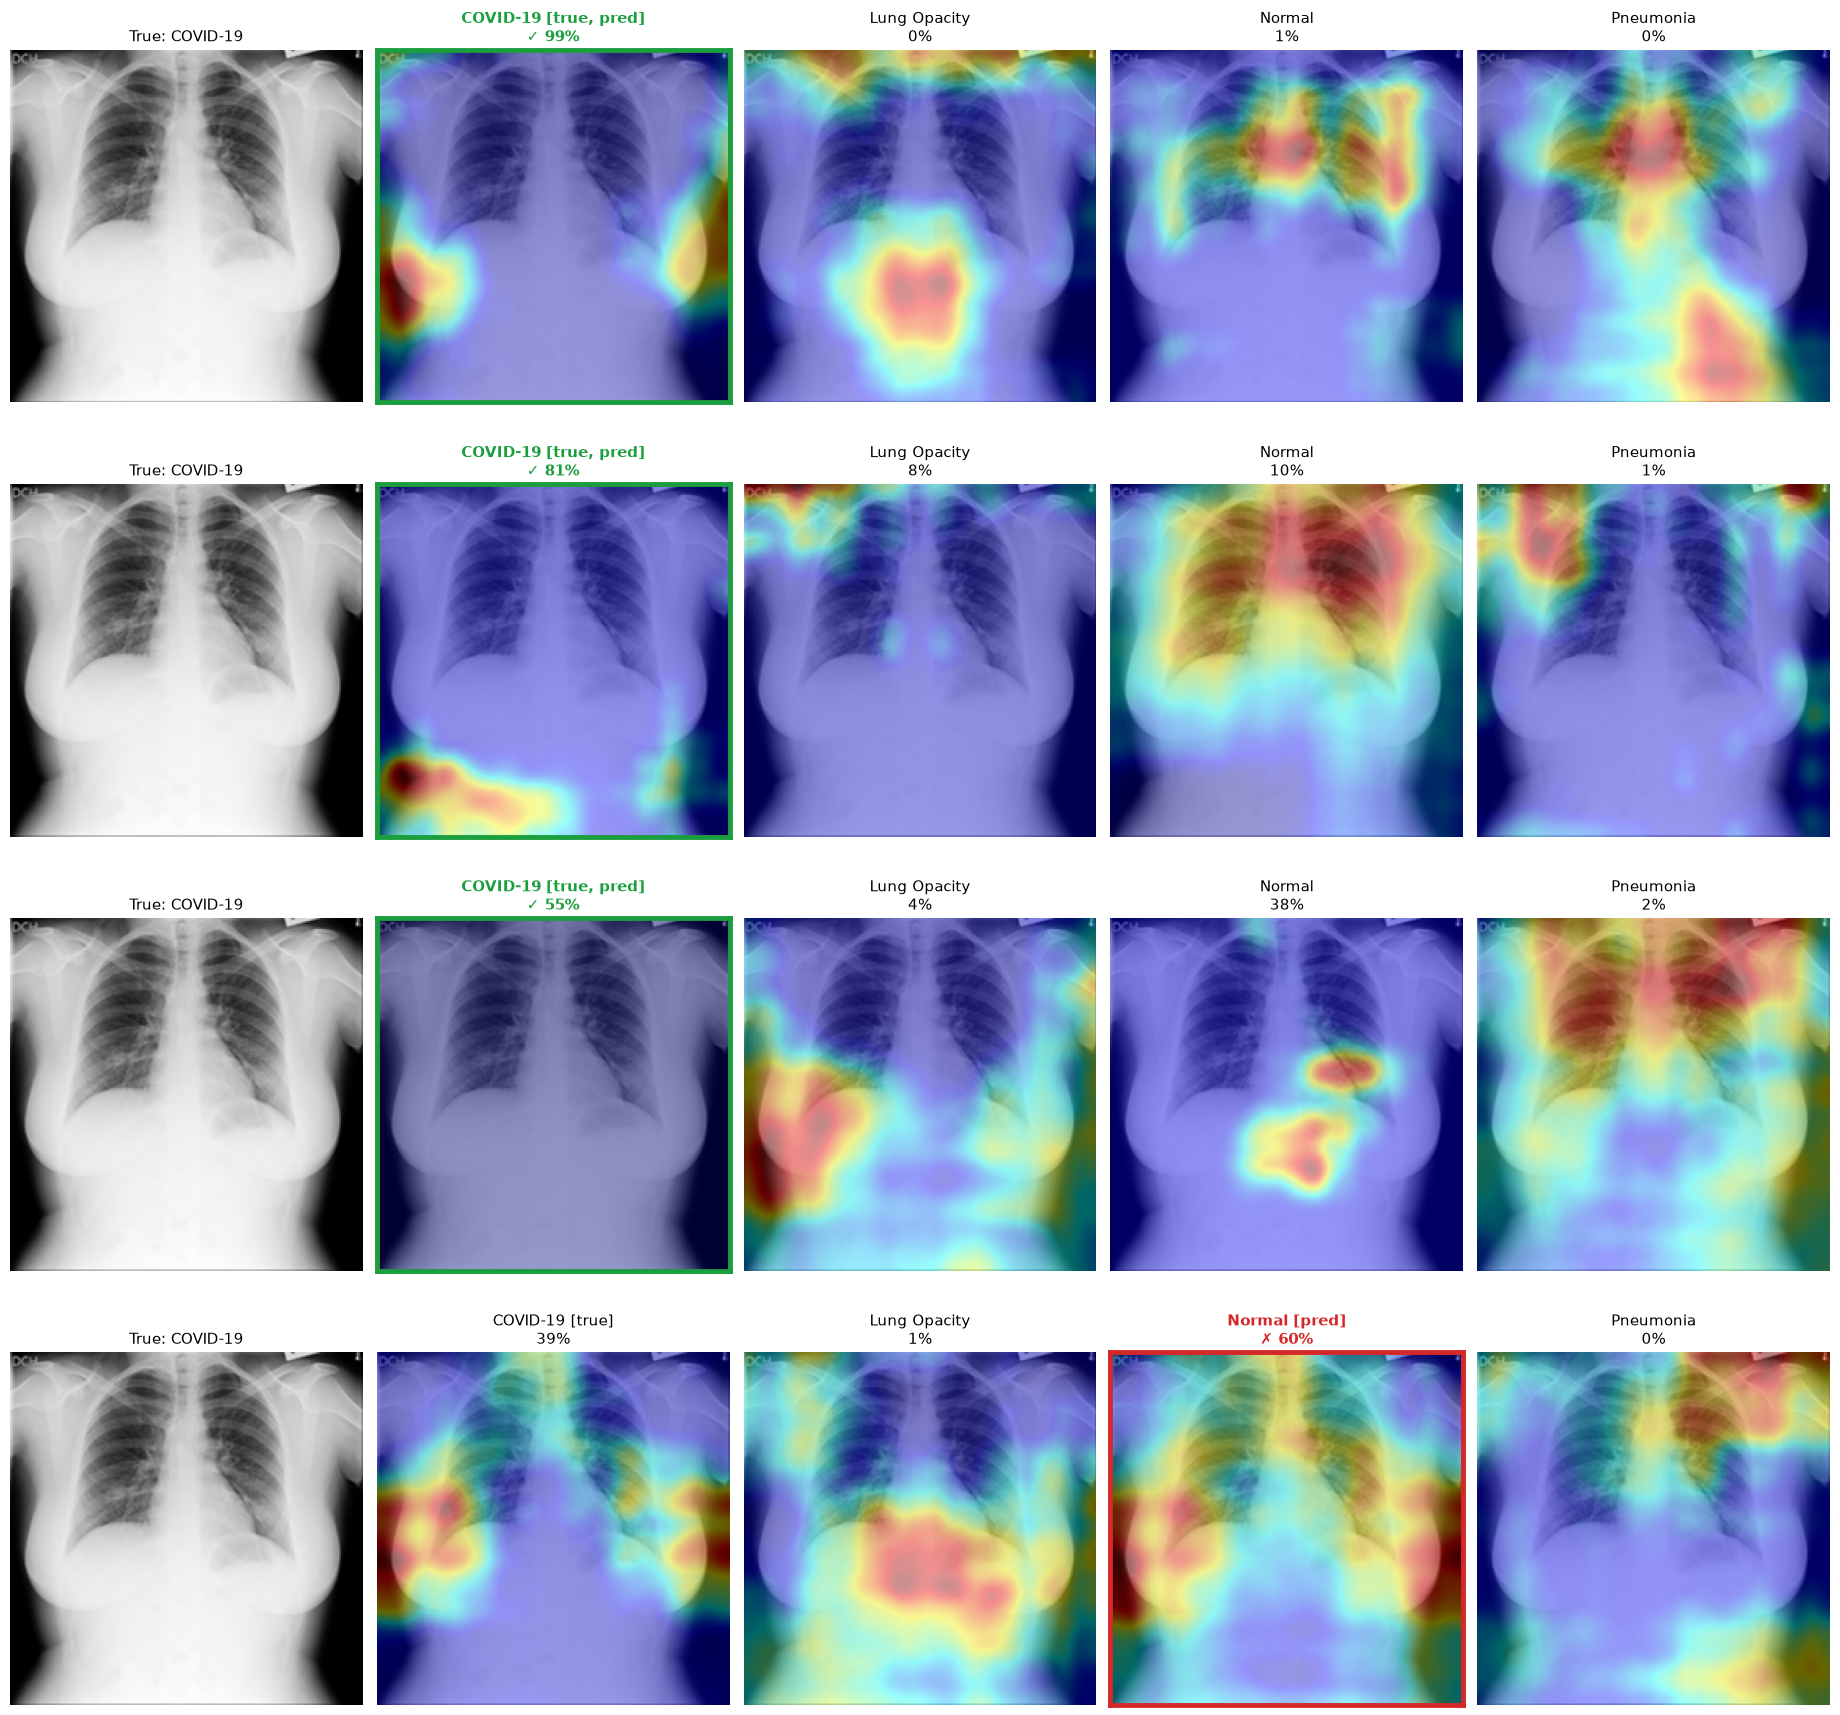

  rows (top to bottom): ['input_masked', 'feature-level-mask', 'inverted-input-mask', 'mask-image-only']


In [11]:
EXPERIMENT = "mask_exp"
out_dir = start_experiment(EXPERIMENT)

for ds_name, model_files in MODEL_SETS[EXPERIMENT].items():
    ds_cfg = DATASETS[ds_name]
    names = ds_cfg["class_names"]
    c = names.index(MASK_EXP_CLASS)
    heading(f"#### {EXPERIMENT}: {ds_cfg['title']} (`{ds_name}`, test image: {names[c]})")
    samples = get_samples(ds_name, ds_cfg)

    by_model = {}
    for model_name, rel_path in model_files.items():
        predictor = try_load(EXPERIMENT, ds_name, ds_cfg, model_name, rel_path)
        if predictor is not None:
            by_model[model_name] = evaluate(predictor, EXPERIMENT, ds_name, ds_cfg, samples, model_name, [c])[c]
            print(f"  {model_name}: {'correct' if by_model[model_name].correct else 'wrong'}")

    if by_model:
        fname = f"{ds_name}__{slug(names[c])}__{'+'.join(slug(m) for m in by_model)}.svg"
        save(render_model_rows(ds_cfg, samples[c], by_model), out_dir / fname)
        print(f"  rows (top to bottom): {list(by_model)}")

<a id="summary"></a>
## 6. Summary
[top](#top)

In [12]:
for experiment in dict.fromkeys(r["experiment"] for r in summary_rows):
    rows = [r for r in summary_rows if r["experiment"] == experiment]
    out_dir = OUT_ROOT / experiment
    heading(f"### Summary: `{experiment}`")
    with open(out_dir / "summary.csv", "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print(f"{'dataset':<10}{'model':<24}correct")
    for ds, m in dict.fromkeys((r["dataset"], r["model"]) for r in rows):
        rs = [r for r in rows if r["dataset"] == ds and r["model"] == m]
        print(f"{ds:<10}{m:<24}{sum(r['correct'] for r in rs)}/{len(rs)}")
    print(f"SVGs: {len(list(out_dir.glob('*.svg')))} in {out_dir}   |   table: {out_dir / 'summary.csv'}\n")

if skipped:
    print("Skipped (fix these and re-run):")
    for ex, ds, m, why in skipped:
        print(f"  {ex} / {ds} / {m}: {why}")

print("\nOne image per class illustrates behaviour; it is not an accuracy estimate.")

### Summary: `datasets`

dataset   model                   correct
rahman    rahman_msr              4/4
cohen     cohen_msr               3/3
kermany   kermany_msr             2/2
SVGs: 3 in c:\Users\dehoa\Downloads\Models\Model Config\results\gradcam_exp\datasets   |   table: c:\Users\dehoa\Downloads\Models\Model Config\results\gradcam_exp\datasets\summary.csv



### Summary: `mask_exp`

dataset   model                   correct
rahman    input_masked            1/1
rahman    feature-level-mask      1/1
rahman    inverted-input-mask     1/1
rahman    mask-image-only         0/1
SVGs: 1 in c:\Users\dehoa\Downloads\Models\Model Config\results\gradcam_exp\mask_exp   |   table: c:\Users\dehoa\Downloads\Models\Model Config\results\gradcam_exp\mask_exp\summary.csv


One image per class illustrates behaviour; it is not an accuracy estimate.
